<a href="https://colab.research.google.com/github/SamikshaaSonavane/EES322_LAB/blob/main/lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install -U geemap

import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print('Packages imported successfully.')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 43.3 MB/s eta 0:00:00
Packages imported successfully.


In [14]:
PROJECT_ID= 'ees322-lab1-samiksha'

ee.Authenticate()
ee.Initialize(project=PROJECT_ID)
print('Earth Engine initialized')

Earth Engine initialized


In [45]:
CENTER_LON = 73.1168
CENTER_LAT = 18.9907

centre = ee.Geometry.Point([CENTER_LON, CENTER_LAT])
aoi = centre.buffer(20_000).bounds()  # 20 km buffer, converted to a bounding rectangle
sample_point = centre

print('AOI created.')

AOI created.


In [46]:
START_DATE = '2025-01-01'
END_DATE   = '2025-12-01'
MAX_CLOUD  = 60  # scene-level cloud cover percentage

raw_collection = (
    ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
    .filterBounds(aoi)
    .filterDate(START_DATE, END_DATE)
    .filter(ee.Filter.lt('CLOUD_COVER', MAX_CLOUD))
)

scene_count = raw_collection.size().getInfo()
print('Number of matching scenes:', scene_count)

if scene_count == 0:
    raise ValueError('No scenes found. Increase the date range or MAX_CLOUD.')

Number of matching scenes: 26


In [47]:
def preprocess_landsat8(image):
    # QA_PIXEL bits used here:
    # bit 1 = dilated cloud
    # bit 2 = cirrus
    # bit 3 = cloud
    # bit 4 = cloud shadow
    # bit 5 = snow
    qa = image.select('QA_PIXEL')

    clear_mask = (
        qa.bitwiseAnd(1 << 1).eq(0)
        .And(qa.bitwiseAnd(1 << 2).eq(0))
        .And(qa.bitwiseAnd(1 << 3).eq(0))
        .And(qa.bitwiseAnd(1 << 4).eq(0))
        .And(qa.bitwiseAnd(1 << 5).eq(0))
    )

    # Keep pixels that are not radiometrically saturated.
    saturation_mask = image.select('QA_RADSAT').eq(0)

    # Apply official Collection 2 scaling to optical surface-reflectance bands.
    optical = image.select('SR_B[1-7]').multiply(0.0000275).add(-0.2)

    return (
        image.addBands(optical, None, True)
        .updateMask(clear_mask)
        .updateMask(saturation_mask)
    )

# Choose the least-cloudy matching scene, then preprocess it.
raw_image = ee.Image(raw_collection.sort('CLOUD_COVER').first())
image = preprocess_landsat8(raw_image)

print('Product ID:', raw_image.get('LANDSAT_PRODUCT_ID').getInfo())
print('Acquisition date:', raw_image.date().format('YYYY-MM-dd').getInfo())
print('Scene cloud cover (%):', raw_image.get('CLOUD_COVER').getInfo())

Product ID: LC08_L2SP_147047_20250214_20250225_02_T1
Acquisition date: 2025-02-14
Scene cloud cover (%): 0


In [48]:
Map = geemap.Map()
Map.centerObject(aoi, 10)

# True colour: Red, Green, Blue = B4, B3, B2
true_color = {
    'bands': ['SR_B4', 'SR_B3', 'SR_B2'],
    'min': 0.0,
    'max': 0.30,
}

# Colour infrared: NIR, Red, Green = B5, B4, B3
false_color = {
    'bands': ['SR_B5', 'SR_B4', 'SR_B3'],
    'min': 0.0,
    'max': 0.35,
}

Map.addLayer(image.clip(aoi), true_color, 'True colour (4-3-2)')
Map.addLayer(image.clip(aoi), false_color, 'False colour (5-4-3)', False)
Map.addLayer(aoi, {'color': 'yellow'}, 'AOI', False)
Map.addLayer(sample_point, {'color': 'red'}, 'Sample point')
Map


Map(center=[18.990701718176087, 73.11712284615797], controls=(WidgetControl(options=['position', 'transparent_…

In [49]:
band_names = [
    ('SR_B1', 'Coastal aerosol'),
    ('SR_B2', 'Blue'),
    ('SR_B3', 'Green'),
    ('SR_B4', 'Red'),
    ('SR_B5', 'NIR'),
    ('SR_B6', 'SWIR1'),
    ('SR_B7', 'SWIR2'),
]

BandMap = geemap.Map()
BandMap.centerObject(aoi, 10)

for band, label in band_names:
    BandMap.addLayer(
        image.select(band).clip(aoi),
        {'min': 0.0, 'max': 0.35},
        label,
        False,
    )

# Show the red band by default.
BandMap.addLayer(image.select('SR_B4').clip(aoi), {'min': 0.0, 'max': 0.35}, 'Red - active')
BandMap.addLayer(sample_point, {'color': 'red'}, 'Sample point')
BandMap

Map(center=[18.990701718176087, 73.11712284615797], controls=(WidgetControl(options=['position', 'transparent_…

Extracted Spectral Data:


,Surface_Type,Wavelength_um,Surface_reflectance
0,Vegetation,0.443,0.046359
1,Vegetation,0.482,0.056953
2,Vegetation,0.562,0.080490
3,Vegetation,0.655,0.099664
4,Vegetation,0.865,0.203599
5,Vegetation,1.609,0.243169
6,Vegetation,2.201,0.167184
7,Water,0.443,0.043825
8,Water,0.482,0.053612
9,Water,0.562,0.080031


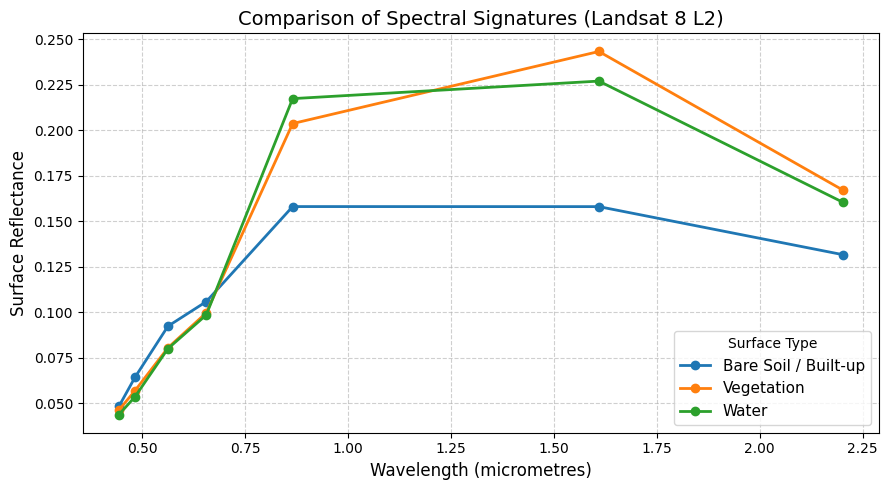

In [44]:
bands = ['SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7']

# Approximate band-centre wavelengths in micrometres.
wavelength_um = [0.443, 0.482, 0.562, 0.655, 0.865, 1.609, 2.201]


# 1. Define 3 specific coordinates [Longitude, Latitude] inside your 20km AOI
# (These coordinates are picked around Navi Mumbai / Panvel area for distinct surfaces)
samples = {
    'Vegetation': ee.Geometry.Point([73.1850, 18.9800]),          # Hills/Forest area
    'Water': ee.Geometry.Point([73.2952, 18.9185]),               # Deep Mumbai Harbor Channel (Inside 20km)
    'Bare Soil / Built-up': ee.Geometry.Point([73.1168, 18.9907]) # Urban/Panvel center
}


bands = ['SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7']
wavelength_um = [0.443, 0.482, 0.562, 0.655, 0.865, 1.609, 2.201]

# 2. Add sample points to your geemap layout for visual verification
for surface_name, pt in samples.items():
    Map.addLayer(pt, {}, f'Sample: {surface_name}')

# 3. Loop through each point and extract spectral reflectance
spectral_list = []

for surface_name, pt in samples.items():
    sample_area = pt.buffer(45)

    spectrum = (
        image.select(bands)
        .reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=sample_area,
            scale=30,
            maxPixels=1_000_000,
        )
        .getInfo()
    )

    # Get reflectance values for each band
    reflectance = [spectrum.get(b, np.nan) for b in bands]

    # Store in list
    for w, r in zip(wavelength_um, reflectance):
        spectral_list.append({
            'Surface_Type': surface_name,
            'Wavelength_um': w,
            'Surface_reflectance': r
        })

# 4. Create master DataFrame
spectral_df = pd.DataFrame(spectral_list)
print("Extracted Spectral Data:")
display(spectral_df.head(21))

# 5. Plot all 3 signatures on a single graph
plt.figure(figsize=(9, 5))

for surface_name, group in spectral_df.groupby('Surface_Type'):
    plt.plot(
        group['Wavelength_um'],
        group['Surface_reflectance'],
        marker='o',
        linewidth=2,
        label=surface_name
    )

plt.xlabel('Wavelength (micrometres)', fontsize=12)
plt.ylabel('Surface Reflectance', fontsize=12)
plt.title('Comparison of Spectral Signatures (Landsat 8 L2)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Surface Type', fontsize=11)
plt.tight_layout()
plt.show()